# Part 3 — Premixed Flames

Freely propagating H$_2$/air flames (`h2o2.yaml`): structure, equilibrium check, transport models, $S_L(\phi)$, $\delta_L(\phi)$, and pressure/preheat effects.

Functions live in `src/ct_utils/free_flame` (flames), `src/ct_utils/general` (equilibrium, fits, saving) and `src/ct_utils/plots`. Tables go to `results/part3/raw/`, figures to `results/part3/figures/{pdf,jpeg}/`.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent / "src"))

import cantera as ct
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import ct_utils
from ct_utils import free_flame as ff
from ct_utils import general as eq
from ct_utils import plots
from ct_utils.opposed_premixed_flame import stoichiometric_mixture_fraction

ct_utils.set_part("part3")      # outputs go to results/part3/
plots.set_style()
%matplotlib inline

ATM = ct.one_atm      # Pa

# Task 1 — 1D Flame Structure

$\phi = 1$, $T_u = 300$ K, 1 atm, mixture-averaged transport.

**`ff.solve_free_flame(phi, T_u, p, transport, fuel, oxidizer, mechanism, width)`** solves a `FreeFlame` (refinement `ratio=2, slope=0.005, curve=0.01`, up to 10 000 points). Results are cached, so repeated calls with the same arguments reuse the solved flame.

**`ff.flame_speed(flame)`** returns $S_L$ = `flame.velocity[0]` (m/s); **`ff.flame_thickness(flame)`** returns $\delta_L$ (m):

$$
\delta_L = \frac{T_b - T_u}{\max\,(\mathrm{d}T/\mathrm{d}x)} \;\sim\; \frac{\alpha}{S_L}
$$

| Symbol | Meaning | SI unit |
|---|---|---|
| $\delta_L$ | Thermal flame thickness | m |
| $T_u$, $T_b$ | Unburned and burned temperature | K |
| $x$ | Position | m |
| $\alpha$ | Thermal diffusivity $k/(\rho c_p)$ | m²/s |
| $S_L$ | Laminar flame speed | m/s |

**`ff.flame_to_dataframe(flame)`** exports the profiles with `to_pandas()` plus $x$, $u$ and the heat release rate.

In [2]:
flame = ff.solve_free_flame(1.0)
eq.save_dataframe(ff.flame_to_dataframe(flame), "flame_phi1_mixavg")

x_mm = flame.grid * 1e3
T_u, T_b = flame.T[0], flame.T[-1]
S_L, delta_L = ff.flame_speed(flame), ff.flame_thickness(flame)
x_f = flame.grid[np.argmax(np.gradient(flame.T, flame.grid))] * 1e3      # steepest point, mm

species = ["H2", "O2", "H2O", "OH", "H"]
Y = [flame.Y[flame.gas.species_index(sp)] for sp in species]
hrr = flame.heat_release_rate / 1e6                                     # MW/m^3

i_hrr = np.argmax(flame.heat_release_rate)
peaks = {sp: x_mm[np.argmax(y)] for sp, y in zip(["OH", "H"], Y[3:])}
print(f"S_L = {S_L * 100:.1f} cm/s,  delta_L = {delta_L * 1e3:.3f} mm,  domain = {x_mm[-1]:.0f} mm "
      f"(delta_L / domain = {delta_L / flame.grid[-1] * 100:.2f} %)")
print(f"HRR peak at x = {x_mm[i_hrr]:.2f} mm where T = {flame.T[i_hrr]:.0f} K; T keeps rising to {T_b:.0f} K at the outlet")
print(f"Peaks: H at {peaks['H']:.2f} mm, OH at {peaks['OH']:.2f} mm (offset {peaks['OH'] - peaks['H']:.2f} mm)")

S_L = 233.1 cm/s,  delta_L = 0.329 mm,  domain = 60 mm (delta_L / domain = 0.55 %)
HRR peak at x = 21.03 mm where T = 997 K; T keeps rising to 2386 K at the outlet
Peaks: H at 21.19 mm, OH at 21.80 mm (offset 0.61 mm)


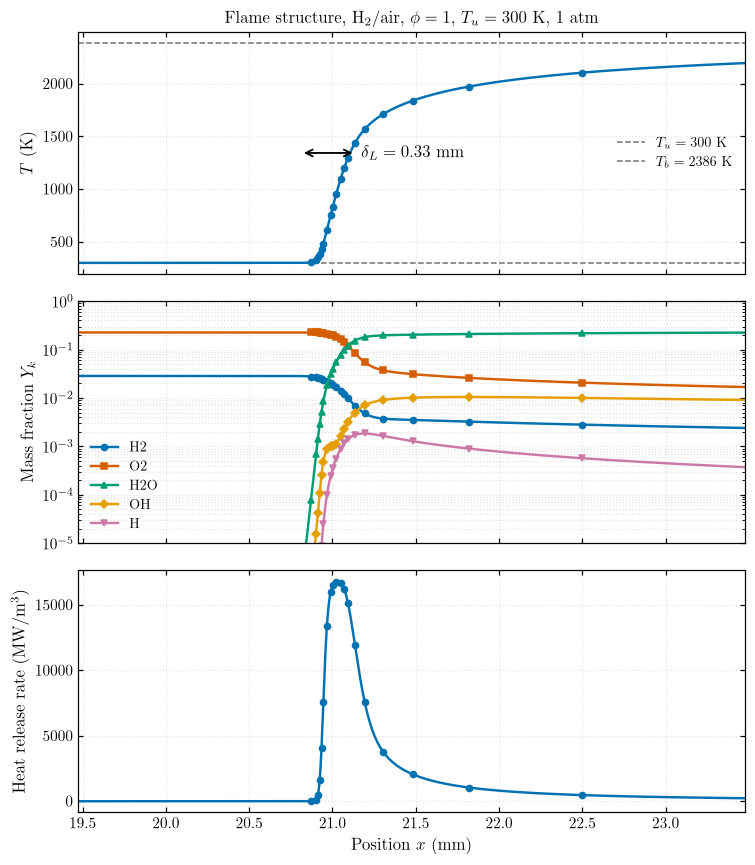

In [3]:
fig, axes = plt.subplots(3, 1, figsize=(7, 8), sharex=True)

plots.plot(x_mm, flame.T, "", r"$T$ (K)", ax=axes[0], markevery=60, legend=True,
           hlines={T_u: rf"$T_u = {T_u:.0f}$ K", T_b: rf"$T_b = {T_b:.0f}$ K"},
           title=r"Flame structure, H$_2$/air, $\phi = 1$, $T_u = 300$ K, 1 atm")
T_mid = 0.5 * (T_u + T_b)
axes[0].annotate("", xy=(x_f - delta_L * 500, T_mid), xytext=(x_f + delta_L * 500, T_mid),
                 arrowprops=dict(arrowstyle="<->", lw=1.2))
axes[0].text(x_f + delta_L * 600, T_mid, rf"$\delta_L = {delta_L * 1e3:.2f}$ mm", va="center")

plots.plot(x_mm, Y, "", "Mass fraction $Y_k$", ax=axes[1], yscale="log", markevery=60,
           labels=[rf"$\mathrm{{{sp}}}$" for sp in species])
axes[1].set_ylim(1e-5, 1)

plots.plot(x_mm, hrr, "Position $x$ (mm)", "Heat release rate (MW/m$^3$)", ax=axes[2],
           markevery=60, legend=False)
axes[2].set_xlim(x_f - 1.5, x_f + 2.5)

fig.tight_layout()
plots.save_figure(fig, "part3_flame_structure")
plt.show()

### Answers

- **HRR vs T peak:** heat release peaks at $x \approx 21.03$ mm where $T \approx 1000$ K, early in the flame. $T$ has no interior peak: it keeps rising to $T_b$ at the outlet. Chain branching ($\mathrm{H + O_2 \rightarrow OH + O}$) and fast exothermic steps peak in the reaction zone. Further downstream, slow three-body radical recombination keeps releasing heat over several mm, so the temperature lags the heat release.
- **OH and H:** not co-located. H peaks at 21.19 mm, inside the reaction zone where it is produced; OH peaks 0.6 mm later at 21.80 mm, because it is removed only by slow recombination and persists into the post-flame gas.
- **Thickness vs domain:** $\delta_L = 0.33$ mm is only 0.55 % of the domain (the solver widened it from 3 to 6 cm), so the flame is very well contained.


# Task 2 — Equilibrium Composition Check

The reference is the HP equilibrium of the same mixture, from **`eq.equilibrium_state(phi)`** (Part 1), not `flame.T[-1]`. The flame's last grid point is compared against it.

In [4]:
gas_eq = eq.equilibrium_state(1.0)
T_err = abs(T_b - gas_eq.T) / gas_eq.T * 100
print(f"T_eq = {gas_eq.T:.1f} K,  T_b = {T_b:.1f} K,  error = {T_err:.2f} %")
assert T_err < 1.0, "tighten the refinement criteria"

species_eq = ["H2O", "H2", "O2", "OH"]
idx = [gas_eq.species_index(sp) for sp in species_eq]
comparison = pd.DataFrame({"species": species_eq, "X_flame": flame.X[idx, -1], "X_eq": gas_eq.X[idx]})
comparison["rel_diff_%"] = (comparison.X_flame - comparison.X_eq).abs() / comparison.X_eq * 100
eq.save_dataframe(comparison, "equilibrium_check")
print(comparison.to_string(index=False, float_format="%.4g"))

T_eq = 2387.6 K,  T_b = 2386.1 K,  error = 0.06 %
species  X_flame     X_eq  rel_diff_%
    H2O    0.324   0.3244      0.1012
     H2   0.0143  0.01457       1.819
     O2 0.005841 0.005609       4.129
     OH 0.007355 0.007285      0.9655


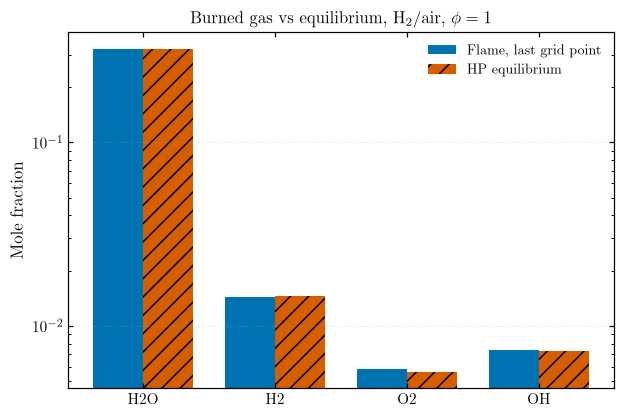

In [5]:
pos, w = np.arange(len(species_eq)), 0.38
fig, ax = plt.subplots(figsize=(6.4, 4.2))
ax.bar(pos - w / 2, comparison.X_flame, w, color=plots.PALETTE[0], label="Flame, last grid point")
ax.bar(pos + w / 2, comparison.X_eq, w, color=plots.PALETTE[1], hatch="//", label="HP equilibrium")
ax.set(xticks=pos, xticklabels=[rf"$\mathrm{{{sp}}}$" for sp in species_eq], yscale="log",
       ylabel="Mole fraction", title=r"Burned gas vs equilibrium, H$_2$/air, $\phi = 1$")
ax.grid(axis="y")
ax.legend()
plots.save_figure(fig, "part3_equilibrium_check")
plt.show()

The flame's burned gas matches equilibrium: $T_b$ is within 0.06 % and every species within about 4 % (O$_2$ is the largest gap, where recombination is still finishing at the outlet). The refinement is adequate.

# Task 3 — Transport Model Comparison

$\phi = 1$, 300 K, 1 atm, `"mixture-averaged"` vs `"unity-Lewis-number"`.

**`ff.flame_position(flame)`** returns the position where $T = T_u + (T_b - T_u)/2$, used to align the fronts at $x = 0$.

In [6]:
flames = {"Mixture-averaged": flame,
          "Le = 1": ff.solve_free_flame(1.0, transport="unity-Lewis-number")}
eq.save_dataframe(ff.flame_to_dataframe(flames["Le = 1"]), "flame_phi1_unityLe")

for name, f in flames.items():
    print(f"{name:<17} S_L = {ff.flame_speed(f) * 100:6.1f} cm/s   delta_L = {ff.flame_thickness(f) * 1e3:.3f} mm")

x_shift = [(f.grid - ff.flame_position(f)) * 1e3 for f in flames.values()]

Mixture-averaged  S_L =  233.1 cm/s   delta_L = 0.329 mm
Le = 1            S_L =  163.9 cm/s   delta_L = 0.293 mm


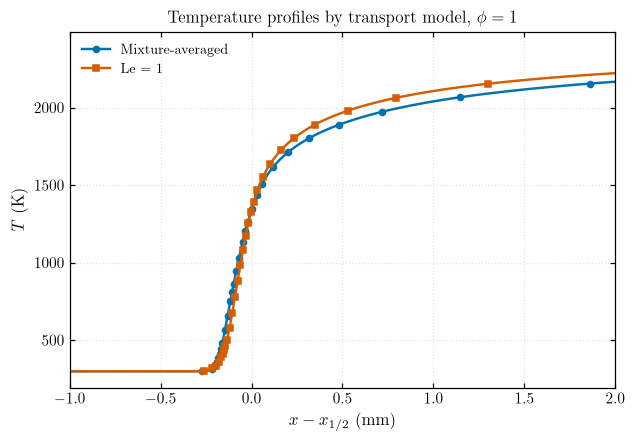

In [7]:
fig, ax = plots.plot(x_shift, [f.T for f in flames.values()], r"$x - x_{1/2}$ (mm)", r"$T$ (K)",
                     labels=list(flames), markevery=40,
                     title=r"Temperature profiles by transport model, $\phi = 1$")
ax.set_xlim(-1, 2)
plots.save_figure(fig, "part3_T_profiles")
plt.show()

**`ff.mixture_fraction(flame, fuel, oxidizer)`** gives $Z(x)$. The page's `flame.mixture_fraction("H2", ...)` does not exist for `FreeFlame` (only for counterflow flames), so $Z$ is evaluated per grid point with a gas object. $Z_\mathrm{st}$ comes from `stoichiometric_mixture_fraction()` (Part 2).

In [8]:
Z_st = stoichiometric_mixture_fraction()
Z = {name: ff.mixture_fraction(f) for name, f in flames.items()}

for name, z in Z.items():
    print(f"{name:<17} Z: min {z.min():.4f}  max {z.max():.4f}  (variation {(z.max() - z.min()) / Z_st * 100:.1f} % of Z_st)")

Mixture-averaged  Z: min 0.0228  max 0.0285  (variation 20.1 % of Z_st)
Le = 1            Z: min 0.0285  max 0.0285  (variation 0.0 % of Z_st)


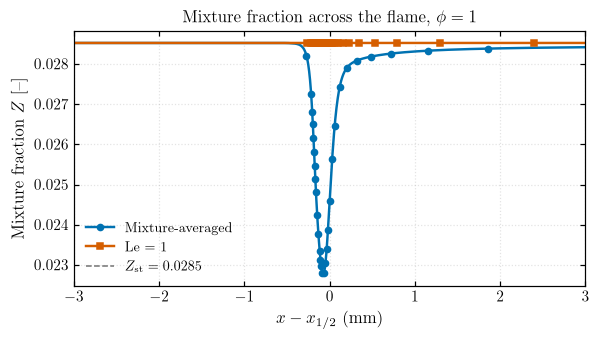

In [9]:
fig, ax = plots.plot(x_shift, list(Z.values()), r"$x - x_{1/2}$ (mm)", r"Mixture fraction $Z$ [--]",
                     figsize=(6, 3), labels=list(flames), markevery=40,
                     hlines={Z_st: rf"$Z_\mathrm{{st}} = {Z_st:.4f}$"},
                     title=r"Mixture fraction across the flame, $\phi = 1$")
ax.set_xlim(-3, 3)
plots.save_figure(fig, "part3_Z_profiles")
plt.show()

### Answers

- **Higher $S_L$ at $\phi = 1$:** mixture-averaged (233 vs 164 cm/s). The light species H$_2$ and H diffuse much faster than heat ($Le_{\mathrm{H_2}} \approx 0.3$, $Le_\mathrm{H} \approx 0.2$). Forcing $D_k = \alpha$ slows the H atoms that diffuse upstream to start chain branching in the preheat zone, so the Le = 1 flame is slower.
- **Non-conserved $Z$:** $Z$ is built from element mass fractions, so it is conserved only if all species diffuse at the same rate. Element conservation in a steady 1D flame gives

$$
\rho u\, Z_\mathrm{H} + J_\mathrm{H} = \text{const} = \rho u\, Z_{\mathrm{H},u}
\quad\Rightarrow\quad
Z_\mathrm{H} = Z_{\mathrm{H},u} - \frac{J_\mathrm{H}}{\rho u}
$$

| Symbol | Meaning | SI unit |
|---|---|---|
| $\rho u$ | Mass flux through the flame (constant) | kg/(m²·s) |
| $Z_\mathrm{H}$ | Mass fraction of element H | – |
| $J_\mathrm{H}$ | Diffusive mass flux of element H (sum over species) | kg/(m²·s) |

Wherever H-carrying species diffuse faster than the rest, $J_\mathrm{H} \ne 0$ and $Z$ departs from its inlet value. **In this run $Z$ does not rise in the preheat zone, as the page expects; it dips by 20 %** (0.0285 → 0.0228) at the reaction zone. H$_2$ diffuses downstream into the reaction zone, down its steep gradient ($J_\mathrm{H} > 0$), so less hydrogen is carried by convection there. No "extra" hydrogen accumulates; it is moved ahead by diffusion and consumed. Under Le = 1 all species diffuse together and $Z$ stays at $Z_\mathrm{st}$ to machine precision.
- **Methane:** much weaker. $Le_{\mathrm{CH_4}} \approx 0.97$, so CH$_4$ diffuses almost exactly like heat and $Z$ would stay nearly constant (small deviations come only from the H and H$_2$ intermediates).


# Task 4 — $S_L(\phi)$ and $\delta_L(\phi)$

**`ff.flame_speed_sweep(phi_range, ...)`** and **`ff.flame_thickness_sweep(phi_range, ...)`** loop `solve_free_flame` over $\phi$ and return arrays in m/s and m. Thanks to the cache, the second sweep reuses the flames of the first.

In [10]:
phi = np.round(np.arange(0.4, 2.51, 0.1), 2)
models = {"Mixture-averaged": "mixture-averaged", "Le = 1": "unity-Lewis-number"}

S_L_phi = {name: ff.flame_speed_sweep(phi, transport=tm) for name, tm in models.items()}
d_L_phi = {name: ff.flame_thickness_sweep(phi, transport=tm) for name, tm in models.items()}

sweep = pd.DataFrame({"phi": phi,
                      **{f"S_L {n} (m/s)": v for n, v in S_L_phi.items()},
                      **{f"delta_L {n} (m)": v for n, v in d_L_phi.items()}})
eq.save_dataframe(sweep, "S_L_delta_L_vs_phi")

ma = "Mixture-averaged"
print(f"S_L peak (mixture-averaged): {S_L_phi[ma].max() * 100:.1f} cm/s at phi = {phi[np.argmax(S_L_phi[ma])]:.1f}")
print(f"Models cross at phi ~ {eq.crossings(phi, S_L_phi[ma] - S_L_phi['Le = 1'], 0.0).round(2)}")
SLd = S_L_phi[ma] * d_L_phi[ma]
print(f"S_L * delta_L (mixture-averaged): {SLd.min() * 1e6:.0f} to {SLd.max() * 1e6:.0f} mm^2/s  over phi = 0.4-2.5")
print(sweep.iloc[::3].to_string(index=False, float_format="%.4g"))

S_L peak (mixture-averaged): 312.8 cm/s at phi = 1.7
Models cross at phi ~ [0.67]
S_L * delta_L (mixture-averaged): 124 to 951 mm^2/s  over phi = 0.4-2.5
 phi  S_L Mixture-averaged (m/s)  S_L Le = 1 (m/s)  delta_L Mixture-averaged (m)  delta_L Le = 1 (m)
 0.4                      0.1617            0.3647                     0.0007641           0.0003862
 0.7                       1.243             1.182                     0.0003306           0.0002691
   1                       2.331             1.639                      0.000329           0.0002926
 1.3                       2.927             1.842                     0.0003118           0.0002922
 1.6                       3.126             1.872                     0.0003039           0.0002999
 1.9                       3.068             1.806                      0.000307           0.0003148
 2.2                       2.886             1.696                     0.0003163           0.0003343
 2.5                       2.656      

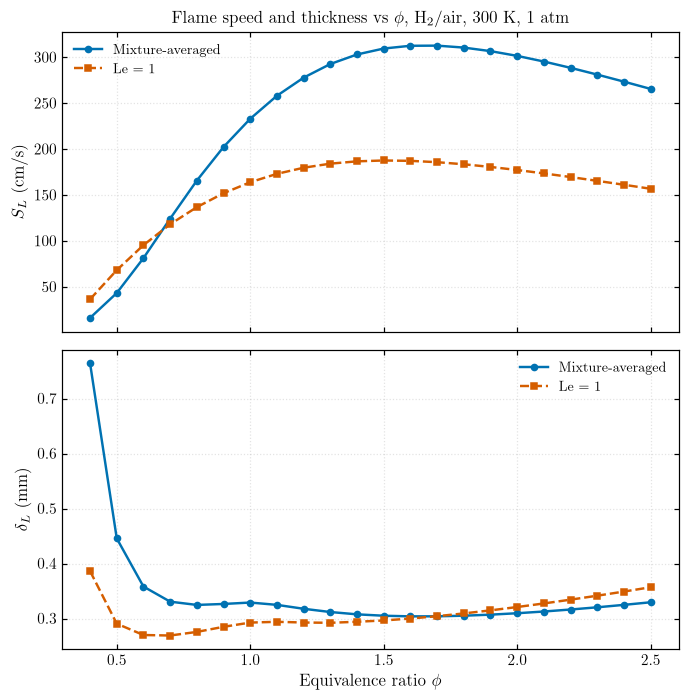

In [11]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(6.4, 6.5), sharex=True)
for (name, s), ls in zip(S_L_phi.items(), ["-", "--"]):
    ax1.plot(phi, s * 100, ls=ls, label=name)
for (name, d), ls in zip(d_L_phi.items(), ["-", "--"]):
    ax2.plot(phi, d * 1e3, ls=ls, label=name)
ax1.set(ylabel=r"$S_L$ (cm/s)", title=r"Flame speed and thickness vs $\phi$, H$_2$/air, 300 K, 1 atm")
ax2.set(xlabel=r"Equivalence ratio $\phi$", ylabel=r"$\delta_L$ (mm)")
for ax in (ax1, ax2):
    ax.grid(True)
    ax.legend()
fig.tight_layout()
plots.save_figure(fig, "part3_SL_deltaL_vs_phi")
plt.show()

### Answers

- **$S_L$ peak:** 313 cm/s at $\phi \approx 1.7$ (mixture-averaged), far richer than the $T_\mathrm{ad}$ peak ($\phi \approx 1.06$, Part 1). Rich H$_2$ mixtures contain more of the fast-diffusing fuel and the H radical pool, which increases reactivity and diffusivity even though the flame is cooler.
- **The gap between the models:** not quite as the page states. The curves **cross at $\phi \approx 0.67$**. Below that, Le = 1 is *faster* (36 vs 16 cm/s at $\phi = 0.4$, a factor 2.3, the largest relative gap). Above it, mixture-averaged is faster, with the largest absolute gap on the rich side ($\approx 126$ cm/s at $\phi = 1.6$–1.7). Lewis-number argument: the unity-Lewis model makes H$_2$ and H diffuse slower but heavy O$_2$ and H$_2$O faster. On the rich side the light-species slowdown dominates; very lean, the deficient reactant is still H$_2$, but the faster heat and O$_2$ transport of the Le = 1 model wins. Planar flames are unstretched, so the thermodiffusive enhancement of lean H$_2$ (cellular flames) does not show up here.
- **$\delta_L$ vs $S_L$:** inversely related. The thin flames are the fast ones ($\delta_L \sim \alpha/S_L$), and $\delta_L$ grows steeply on the lean side where $S_L$ collapses. But $S_L\delta_L$ varies a lot with $\phi$ (124 to 951 mm²/s), because the relevant diffusivity changes with the burned temperature and composition.


# Task 5 — Pressure and Preheat

$\phi = 1$, both transport models (the page asks for mixture-averaged; Le = 1 is kept for comparison). $p \in [1, 10]$ atm and $T_u \in [300, 700]$ K, 20 points each.

**`eq.power_law_fit(x, y)`** fits $y = C x^n$ as a straight line on log–log axes and returns `(C, n)`; the fits are drawn dotted.

## 5a — Pressure sweep

In [12]:
phi = 1.0
p_atm = np.geomspace(1, 10, 20)                     # atm

S_L_p = {name: np.empty_like(p_atm) for name in models}
d_L_p = {name: np.empty_like(p_atm) for name in models}

for name, tm in models.items():
    for i, p in enumerate(p_atm):
        flame_p = ff.solve_free_flame(phi, p=p * ATM, transport=tm)
        S_L_p[name][i] = ff.flame_speed(flame_p)
        d_L_p[name][i] = ff.flame_thickness(flame_p)

fit_S_p = {name: eq.power_law_fit(p_atm, S_L_p[name]) for name in models}
fit_d_p = {name: eq.power_law_fit(p_atm, d_L_p[name]) for name in models}

eq.save_dataframe(pd.DataFrame({"p_atm": p_atm,
                                **{f"S_L {n} (m/s)": v for n, v in S_L_p.items()},
                                **{f"delta_L {n} (m)": v for n, v in d_L_p.items()}}), "pressure_sweep")

for name in models:
    (C_S, n_S), (C_d, n_d) = fit_S_p[name], fit_d_p[name]
    print(f"{name:<17} S_L = {C_S:.3f} p^{n_S:.3f} m/s     delta_L = {C_d:.3e} p^{n_d:.3f} m   (p in atm)")

Mixture-averaged  S_L = 2.516 p^-0.184 m/s     delta_L = 3.104e-04 p^-1.150 m   (p in atm)
Le = 1            S_L = 1.719 p^-0.031 m/s     delta_L = 2.813e-04 p^-1.131 m   (p in atm)


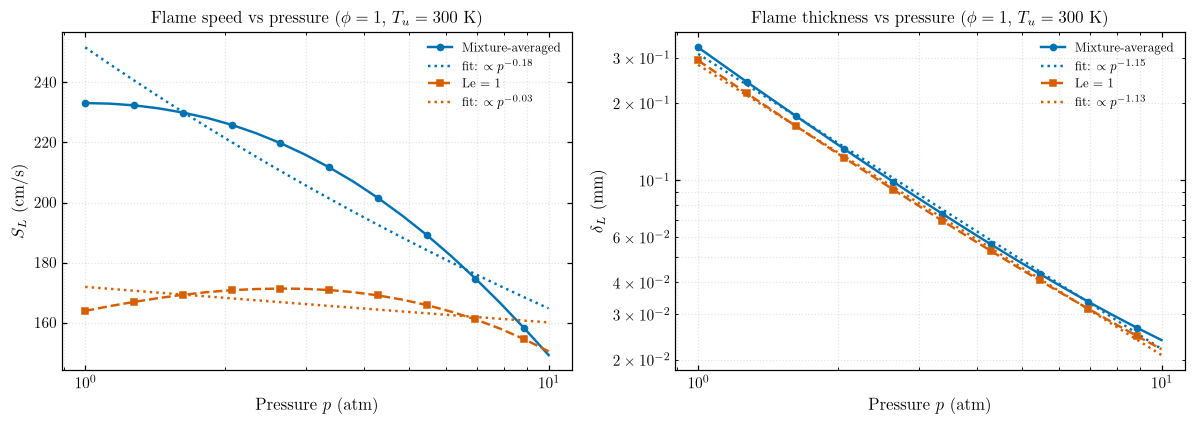

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

for (name, color), ls in zip(zip(models, plots.PALETTE), ["-", "--"]):
    C, n = fit_S_p[name]
    axes[0].plot(p_atm, S_L_p[name] * 100, ls=ls, color=color, markevery=2, label=name)
    axes[0].plot(p_atm, C * p_atm**n * 100, ":", color=color, marker="none", label=rf"fit: $\propto p^{{{n:.2f}}}$")
    C, n = fit_d_p[name]
    axes[1].plot(p_atm, d_L_p[name] * 1e3, ls=ls, color=color, markevery=2, label=name)
    axes[1].plot(p_atm, C * p_atm**n * 1e3, ":", color=color, marker="none", label=rf"fit: $\propto p^{{{n:.2f}}}$")

axes[0].set(xscale="log", xlabel=r"Pressure $p$ (atm)", ylabel=r"$S_L$ (cm/s)",
            title=r"Flame speed vs pressure ($\phi = 1$, $T_u = 300$ K)")
axes[1].set(xscale="log", yscale="log", xlabel=r"Pressure $p$ (atm)", ylabel=r"$\delta_L$ (mm)",
            title=r"Flame thickness vs pressure ($\phi = 1$, $T_u = 300$ K)")
for ax in axes:
    ax.grid(True, which="both")
    ax.legend(fontsize=8)

fig.tight_layout()
plots.save_figure(fig, "part3_pressure_sweep")
plt.show()

## 5b — Preheat sweep

In [14]:
T_u_range = np.linspace(300, 700, 20)              # K

S_L_T = {name: np.empty_like(T_u_range) for name in models}
d_L_T = {name: np.empty_like(T_u_range) for name in models}

for name, tm in models.items():
    for i, T in enumerate(T_u_range):
        flame_T = ff.solve_free_flame(phi, T_u=T, transport=tm)
        S_L_T[name][i] = ff.flame_speed(flame_T)
        d_L_T[name][i] = ff.flame_thickness(flame_T)

fit_S_T = {name: eq.power_law_fit(T_u_range, S_L_T[name]) for name in models}
fit_d_T = {name: eq.power_law_fit(T_u_range, d_L_T[name]) for name in models}

eq.save_dataframe(pd.DataFrame({"T_u": T_u_range,
                                **{f"S_L {n} (m/s)": v for n, v in S_L_T.items()},
                                **{f"delta_L {n} (m)": v for n, v in d_L_T.items()}}), "preheat_sweep")

for name in models:
    print(f"{name:<17} S_L ~ T_u^{fit_S_T[name][1]:.3f}     delta_L ~ T_u^{fit_d_T[name][1]:.3f}")

Mixture-averaged  S_L ~ T_u^1.687     delta_L ~ T_u^0.430
Le = 1            S_L ~ T_u^1.601     delta_L ~ T_u^0.223


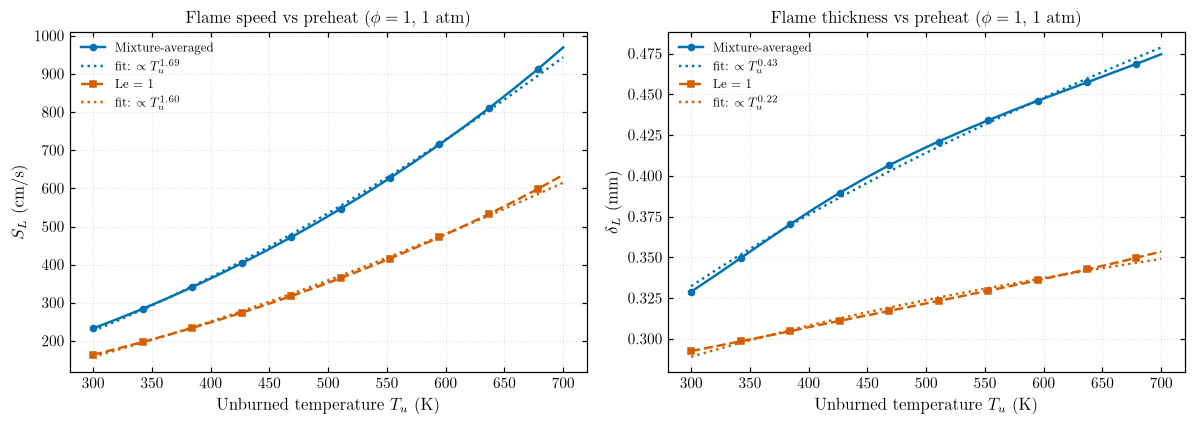

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

for (name, color), ls in zip(zip(models, plots.PALETTE), ["-", "--"]):
    C, m = fit_S_T[name]
    axes[0].plot(T_u_range, S_L_T[name] * 100, ls=ls, color=color, markevery=2, label=name)
    axes[0].plot(T_u_range, C * T_u_range**m * 100, ":", color=color, marker="none", label=rf"fit: $\propto T_u^{{{m:.2f}}}$")
    C, m = fit_d_T[name]
    axes[1].plot(T_u_range, d_L_T[name] * 1e3, ls=ls, color=color, markevery=2, label=name)
    axes[1].plot(T_u_range, C * T_u_range**m * 1e3, ":", color=color, marker="none", label=rf"fit: $\propto T_u^{{{m:.2f}}}$")

axes[0].set(xlabel=r"Unburned temperature $T_u$ (K)", ylabel=r"$S_L$ (cm/s)",
            title=r"Flame speed vs preheat ($\phi = 1$, 1 atm)")
axes[1].set(xlabel=r"Unburned temperature $T_u$ (K)", ylabel=r"$\delta_L$ (mm)",
            title=r"Flame thickness vs preheat ($\phi = 1$, 1 atm)")
for ax in axes:
    ax.grid(True)
    ax.legend(fontsize=8)

fig.tight_layout()
plots.save_figure(fig, "part3_preheat_sweep")
plt.show()

## 5c — $S_L\delta_L$ and preheat vs pressure

$S_L\delta_L$ is shown raw and divided by the unburned thermal diffusivity $\alpha_u = k/(\rho c_p)$ at the inlet (mixture-averaged).

In [16]:
ma = "Mixture-averaged"
flames_p = [ff.solve_free_flame(phi, p=p * ATM) for p in p_atm]
alpha_u = np.array([f.thermal_conductivity[0] / (f.density[0] * f.cp_mass[0]) for f in flames_p])   # m^2/s
SLd_p = S_L_p[ma] * d_L_p[ma]                                                                       # m^2/s

S_L_ref = ff.flame_speed(ff.solve_free_flame(phi))
S_L_500K = ff.flame_speed(ff.solve_free_flame(phi, T_u=500.0))
S_L_2atm = ff.flame_speed(ff.solve_free_flame(phi, p=2 * ATM))

print(f"S_L: 300 K, 1 atm = {S_L_ref * 100:.1f} cm/s | +200 K preheat = {S_L_500K * 100:.1f} cm/s "
      f"({(S_L_500K / S_L_ref - 1) * 100:+.0f} %) | 2 atm = {S_L_2atm * 100:.1f} cm/s ({(S_L_2atm / S_L_ref - 1) * 100:+.0f} %)")
print(f"S_L*delta_L: {SLd_p[0] * 1e6:.0f} -> {SLd_p[-1] * 1e6:.0f} mm^2/s from 1 to 10 atm;  "
      f"S_L*delta_L/alpha_u: {(SLd_p / alpha_u).min():.1f} to {(SLd_p / alpha_u).max():.1f}")

S_L: 300 K, 1 atm = 233.1 cm/s | +200 K preheat = 527.3 cm/s (+126 %) | 2 atm = 226.5 cm/s (-3 %)
S_L*delta_L: 767 -> 36 mm^2/s from 1 to 10 atm;  S_L*delta_L/alpha_u: 7.7 to 16.5


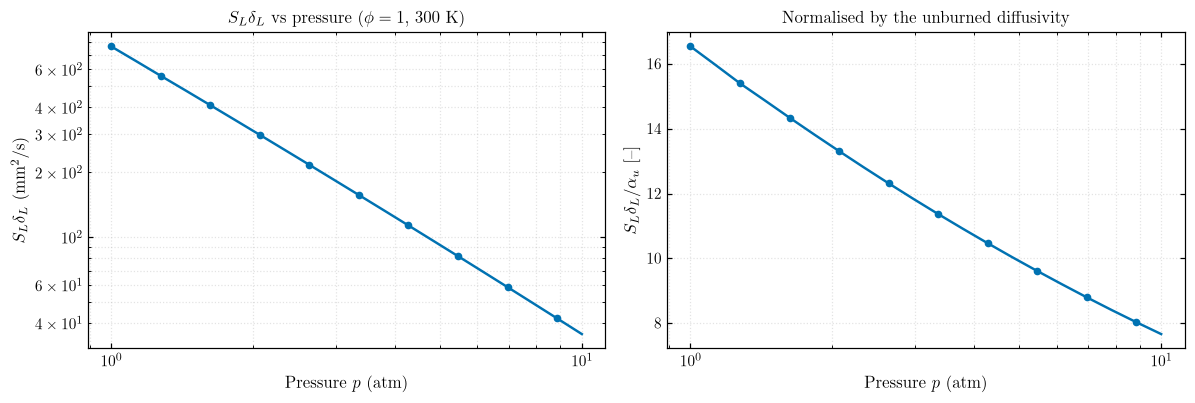

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
plots.plot(p_atm, SLd_p * 1e6, r"Pressure $p$ (atm)", r"$S_L \delta_L$ (mm$^2$/s)", ax=axes[0],
           xscale="log", yscale="log", legend=False, markevery=2,
           title=r"$S_L \delta_L$ vs pressure ($\phi = 1$, 300 K)")
plots.plot(p_atm, SLd_p / alpha_u, r"Pressure $p$ (atm)", r"$S_L \delta_L / \alpha_u$ [--]", ax=axes[1],
           xscale="log", legend=False, markevery=2, title=r"Normalised by the unburned diffusivity")
fig.tight_layout()
plots.save_figure(fig, "part3_SLdelta_vs_p")
plt.show()

### Answers

- **Exponents (mixture-averaged):** $S_L \propto p^{-0.18}$, not the $\approx -0.5$ the page expects. $S_L(p)$ is not a power law: its local slope steepens from $\approx 0$ at 1 atm to $\approx -0.5$ at 10 atm, which the dotted fit cannot follow. Under Le = 1, $S_L$ even rises slightly up to $\approx 3$ atm before falling ($n = -0.03$). Thickness is a clean power law for both models: $\delta_L \propto p^{-1.15}$ and $p^{-1.13}$. Preheat gives $S_L \propto T_u^{1.69}$ (Le = 1: $T_u^{1.60}$), inside the typical 1.5–2.0, so H$_2$ follows the usual trend; $\delta_L \propto T_u^{0.43}$.
- **Why $S_L$ falls with $p$ and $\delta_L$ falls faster:** $S_L \sim \sqrt{\alpha\,\omega}$ with $\alpha \propto 1/p$. If the overall rate scaled as $\omega \propto p$, $S_L$ would not change; it falls because the three-body step $\mathrm{H + O_2 + M \rightarrow HO_2 + M}$ strengthens with pressure and competes with chain branching. Meanwhile $\delta_L \sim \alpha / S_L$ carries the full $1/p$ of $\alpha$, so it falls almost as $p^{-1}$.
- **Preheat vs pressure:** +200 K preheat raises $S_L$ from 233 to 527 cm/s (+126 %); doubling $p$ to 2 atm lowers it to 227 cm/s (−3 %). Preheat is by far the stronger lever, which is why high-inlet-temperature and recuperated combustors face flashback risk with H$_2$, and why high pressure alone does not slow a flame much.
- **$S_L \delta_L$:** it has units of diffusivity and approximates the thermal diffusivity $\alpha$, since $\delta_L \sim \alpha/S_L$. It is **not constant with pressure** here: it drops from 767 to 36 mm²/s between 1 and 10 atm, because $\alpha \propto 1/p$. Normalising by the unburned $\alpha_u$ removes most of that: $S_L\delta_L/\alpha_u$ only varies from about 8 to 17. It stays above 1 because $\delta_L$ is set by the hot gas, where $\alpha$ is much larger than at 300 K.
